In [1]:
!pip install polars matplotlib seaborn


In [2]:
import time
import tracemalloc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)
n_rows = 1_000_000

print(f"Generating synthetic dataset with {n_rows:,} rows...")
data = {
    "id": np.arange(n_rows),
    "category": np.random.choice(["A", "B", "C", "D"], size=n_rows),
    "value": np.random.uniform(10, 500, size=n_rows),
    "quantity": np.random.randint(1, 20, size=n_rows),
    "date": np.random.choice(pd.date_range("2025-01-01", "2026-01-01"), size=n_rows)
}

# Save as CSV so both libraries read from disk identically
pdf_temp = pd.DataFrame(data)
pdf_temp.to_csv("benchmark_data.csv", index=False)
print("Dataset created and saved as 'benchmark_data.csv'!")

Generating synthetic dataset with 1,000,000 rows...
Dataset created and saved as 'benchmark_data.csv'!


In [5]:
import time
import tracemalloc
import pandas as pd
import polars as pl
import numpy as np

# Helper function to measure time and memory
def benchmark_op(func, iterations=3):
    times = []
    memories = []
    for _ in range(iterations):
        tracemalloc.start()
        start = time.perf_counter()

        result = func() # Execute operation

        end = time.perf_counter()
        current, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        times.append(end - start)
        memories.append(peak / 1024 / 1024) # Convert to MB
    return np.median(times), np.median(memories), result

results = []

# --- 1. LOAD DATASET ---
pd_time, pd_mem, df_pd = benchmark_op(lambda: pd.read_csv("benchmark_data.csv"))
pl_time, pl_mem, df_pl = benchmark_op(lambda: pl.read_csv("benchmark_data.csv"))
results.append(["Load Dataset", pd_time, pl_time, pd_mem, pl_mem])

# --- 2. FILTER ROWS ---
pd_time, pd_mem, _ = benchmark_op(lambda: df_pd[df_pd["value"] > 250])
pl_time, pl_mem, _ = benchmark_op(lambda: df_pl.filter(pl.col("value") > 250))
results.append(["Filter Rows", pd_time, pl_time, pd_mem, pl_mem])

# --- 3. SELECT COLUMNS ---
pd_time, pd_mem, _ = benchmark_op(lambda: df_pd[["id", "category", "value"]])
pl_time, pl_mem, _ = benchmark_op(lambda: df_pl.select(["id", "category", "value"]))
results.append(["Select Columns", pd_time, pl_time, pd_mem, pl_mem])

# --- 4. GROUP & AGGREGATE ---
pd_time, pd_mem, _ = benchmark_op(lambda: df_pd.groupby("category").agg({"value": "mean", "quantity": "sum"}))
# FIXED parenthesization/bracket syntax here:
pl_time, pl_mem, _ = benchmark_op(lambda: df_pl.group_by("category").agg([pl.col("value").mean(), pl.col("quantity").sum()]))
results.append(["Group & Aggregate", pd_time, pl_time, pd_mem, pl_mem])

# --- 5. JOIN DATASETS ---
# Create a small secondary lookup dataframe for joining
lookup_data = pd.DataFrame({"category": ["A", "B", "C", "D"], "discount": [0.1, 0.15, 0.2, 0.05]})
lookup_data.to_csv("lookup.csv", index=False)

df_pd_lookup = pd.read_csv("lookup.csv")
df_pl_lookup = pl.read_csv("lookup.csv")

pd_time, pd_mem, _ = benchmark_op(lambda: pd.merge(df_pd, df_pd_lookup, on="category", how="inner"))
pl_time, pl_mem, _ = benchmark_op(lambda: df_pl.join(df_pl_lookup, on="category", how="inner"))
results.append(["Join Datasets", pd_time, pl_time, pd_mem, pl_mem])

# --- 6. SORT & TRANSFORM ---
pd_time, pd_mem, _ = benchmark_op(lambda: df_pd.sort_values(by="value", ascending=False).assign(total_cost = lambda x: x.value * x.quantity))
pl_time, pl_mem, _ = benchmark_op(lambda: df_pl.sort(by="value", descending=True).with_columns((pl.col("value") * pl.col("quantity")).alias("total_cost")))
results.append(["Sort & Transform", pd_time, pl_time, pd_mem, pl_mem])

# --- DISPLAY RESULTS TABLE ---
summary_df = pd.DataFrame(results, columns=["Operation", "Pandas Time (s)", "Polars Time (s)", "Pandas Peak Mem (MB)", "Polars Peak Mem (MB)"])
print(summary_df.to_markdown(index=False))

| Operation         |   Pandas Time (s) |   Polars Time (s) |   Pandas Peak Mem (MB) |   Polars Peak Mem (MB) |
|:------------------|------------------:|------------------:|-----------------------:|-----------------------:|
| Load Dataset      |         1.05881   |       0.350629    |               122.251  |             0.00183868 |
| Filter Rows       |         0.0327136 |       0.0154708   |                28.1726 |             0.00283527 |
| Select Columns    |         0.0190905 |       0.000676834 |                22.893  |             0.00223255 |
| Group & Aggregate |         0.140003  |       0.0616667   |                47.5152 |             0.00322437 |
| Join Datasets     |         0.203938  |       0.186856    |                61.0495 |             0.00210571 |
| Sort & Transform  |         0.211247  |       0.160061    |                99.1953 |             0.00247669 |


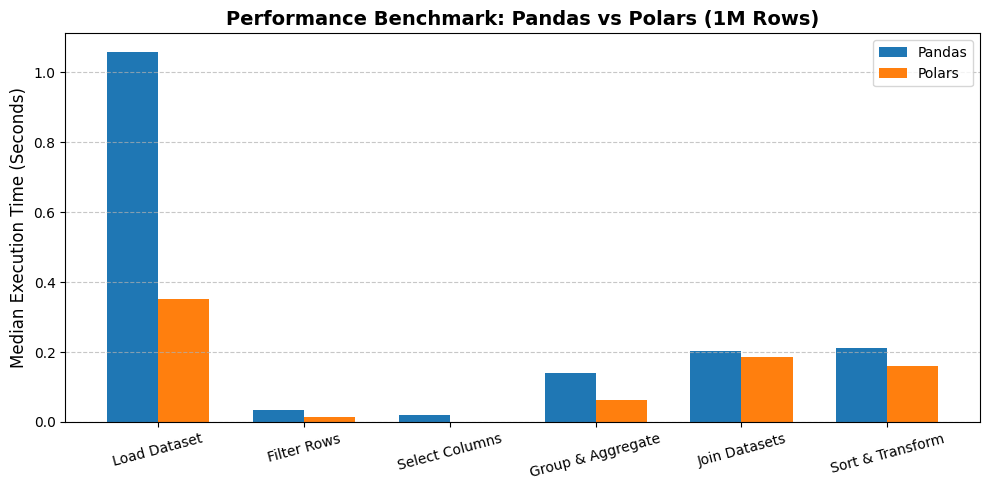

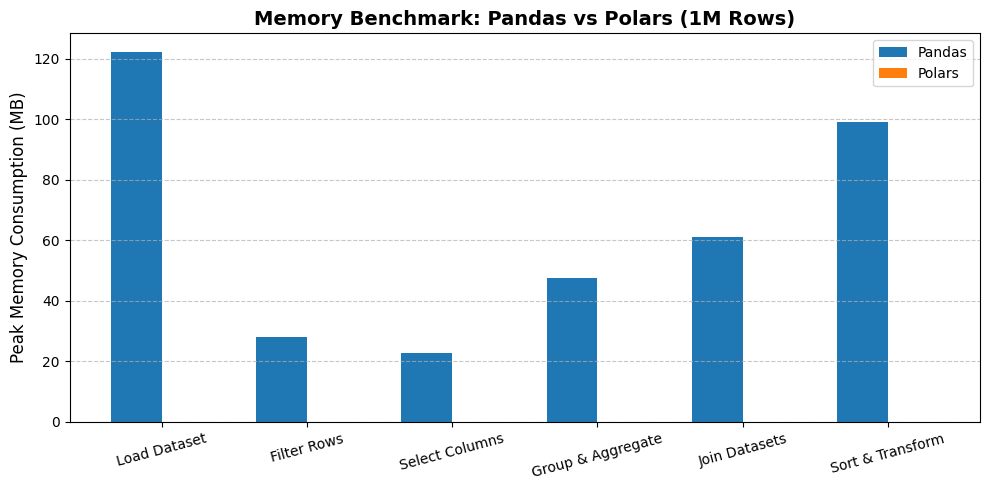

In [6]:
import matplotlib.pyplot as plt
import numpy as np

operations = summary_df["Operation"].tolist()
pd_times = summary_df["Pandas Time (s)"].tolist()
pl_times = summary_df["Polars Time (s)"].tolist()
pd_mems = summary_df["Pandas Peak Mem (MB)"].tolist()
pl_mems = summary_df["Polars Peak Mem (MB)"].tolist()

x = np.arange(len(operations))
width = 0.35


fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(x - width/2, pd_times, width, label='Pandas', color='#1f77b4')
ax1.bar(x + width/2, pl_times, width, label='Polars', color='#ff7f0e')
ax1.set_ylabel('Median Execution Time (Seconds)', fontsize=12)
ax1.set_title('Performance Benchmark: Pandas vs Polars (1M Rows)', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(operations, rotation=15)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


fig, ax2 = plt.subplots(figsize=(10, 5))
ax2.bar(x - width/2, pd_mems, width, label='Pandas', color='#1f77b4')
ax2.bar(x + width/2, pl_mems, width, label='Polars', color='#ff7f0e')
ax2.set_ylabel('Peak Memory Consumption (MB)', fontsize=12)
ax2.set_title('Memory Benchmark: Pandas vs Polars (1M Rows)', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(operations, rotation=15)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()